Figures and `numbers.tex`, read only from `results/`. `results/export/` mirrors the Overleaf layout (`numbers.tex`, `images/*.pdf`): drag and drop.
rcParams match the thesis: figures are included at `width=\textwidth`, no rescaling.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np

from thesis.config import REPO_ROOT

results = json.loads((REPO_ROOT / "results" / "results.json").read_text())
export_dir = REPO_ROOT / "results" / "export"
image_dir = export_dir / "images"
image_dir.mkdir(parents=True, exist_ok=True)

BODY_PT = 11  # \documentclass[11pt]
TEXTWIDTH_PT = 455.24  # A4 minus 2 x 2.5 cm; confirm with \showthe\textwidth
width = TEXTWIDTH_PT / 72.27
plt.rcParams.update(
    {
        "font.size": BODY_PT,
        "axes.titlesize": BODY_PT,
        "axes.labelsize": BODY_PT,
        "legend.fontsize": BODY_PT,
        "xtick.labelsize": BODY_PT,
        "ytick.labelsize": BODY_PT,
        "figure.figsize": (width, 0.6 * width),
        "figure.constrained_layout.use": True,
        "pdf.fonttype": 42,
    }
)
MODELS = ["anthropic", "google", "openai"]
BINS = [-5, -3, 3, 5, 10, 20, 40, 80]


def bin_key(b):
    return f"m{-b}" if b < 0 else f"p{b}"

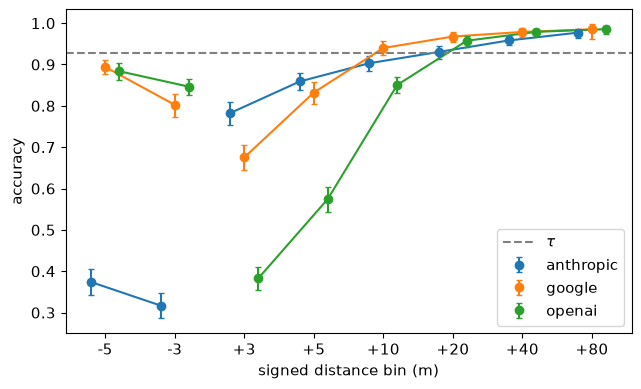

In [2]:
# accuracy per bin with 95% CI error bars, joined within each side, tau line
fig, ax = plt.subplots()
for i, m in enumerate(MODELS):
    keys = [f"verification_accuracy_{m}_{bin_key(b)}" for b in BINS]
    acc = np.array([results[k] for k in keys])
    low = np.array([results[f"{k}_ci_low"] for k in keys])
    high = np.array([results[f"{k}_ci_high"] for k in keys])
    x = np.arange(len(BINS)) + (i - 1) * 0.2
    color = ax.errorbar(x, acc, yerr=[acc - low, high - acc], fmt="o", capsize=2, label=m)[0].get_color()
    inside = np.array(BINS) < 0
    for side in (inside, ~inside):  # gap at the edge
        ax.plot(x[side], acc[side], color=color)
ax.axhline(results["tau"], color="grey", linestyle="--", label=r"$\tau$")
ax.set_xticks(range(len(BINS)), [f"{b:+d}" for b in BINS])
ax.set_xlabel("signed distance bin (m)")
ax.set_ylabel("accuracy")
ax.legend()
fig.savefig(image_dir / "accuracy_by_bin.pdf")

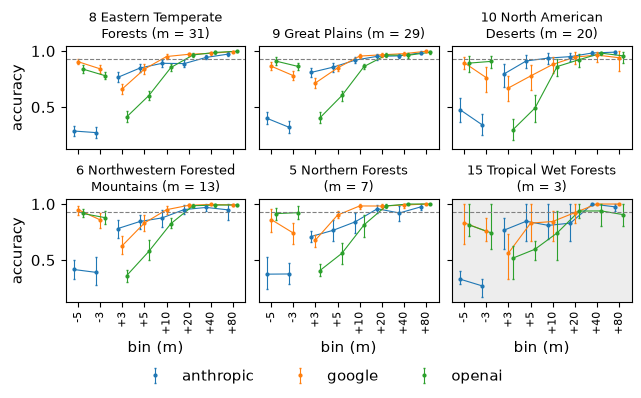

In [3]:
# accuracy per bin for the 5 largest ecoregions + the 3-box ecoregion (analysis.json); m = boxes, grey panel = 3 boxes
import textwrap

import pandas as pd

analysis = json.loads((REPO_ROOT / "results" / "analysis.json").read_text())
boxes = pd.read_parquet(REPO_ROOT / "data" / "dataset_v2" / "inventory" / "boxes.parquet")
ecoregions = boxes.groupby("ecoregion_code").agg(name=("ecoregion_name", "first"), boxes=("box_id", "size"))
ecoregions = pd.concat([ecoregions.nlargest(5, "boxes"), ecoregions[ecoregions["boxes"] == 3]])
ecoregions = ecoregions.sort_values("boxes", ascending=False)

fig, axes = plt.subplots(2, 3, figsize=(width, 0.62 * width), sharex=True, sharey=True)
inside = np.array(BINS) < 0
for ax, (code, eco) in zip(axes.flat, ecoregions.iterrows()):
    for i, m in enumerate(MODELS):
        keys = [f"verification_accuracy_{m}_{bin_key(b)}_ecoregion_{code}" for b in BINS]
        acc = np.array([analysis[k] for k in keys])
        low = np.array([analysis[f"{k}_ci_low"] for k in keys])
        high = np.array([analysis[f"{k}_ci_high"] for k in keys])
        x = np.arange(len(BINS)) + (i - 1) * 0.2
        color = ax.errorbar(
            x, acc, yerr=[acc - low, high - acc], fmt="o", markersize=2, capsize=1, linewidth=0.8, label=m
        )[0].get_color()
        for side in (inside, ~inside):
            ax.plot(x[side], acc[side], color=color, linewidth=0.8)
    ax.axhline(results["tau"], color="grey", linestyle="--", linewidth=0.8)
    ax.set_title(textwrap.fill(f"{code} {eco['name'].title()} (m\u00a0=\u00a0{eco['boxes']})", 24), fontsize=9)
    if eco["boxes"] == 3:
        ax.set_facecolor("0.93")
ax.set_xticks(range(len(BINS)), [f"{b:+d}" for b in BINS])
for ax in axes[-1]:
    ax.tick_params(axis="x", labelsize=8, labelrotation=90)
    ax.set_xlabel("bin (m)")
for ax in axes[:, 0]:
    ax.set_ylabel("accuracy")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=len(MODELS), frameon=False)
fig.savefig(image_dir / "accuracy_by_ecoregion.pdf")

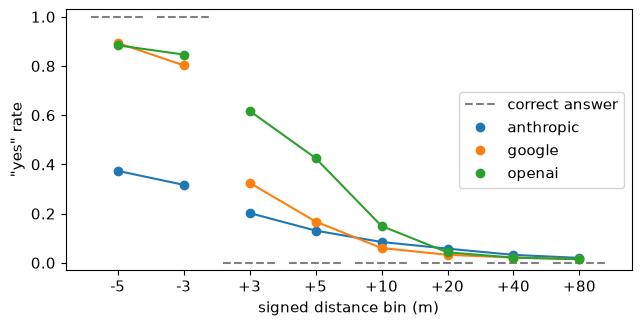

In [4]:
# task 1 "yes" rate per bin (weighted point estimate, invalid = not "yes"); grey = correct answer (1 inside, 0 outside)
fig, ax = plt.subplots(figsize=(width, 0.5 * width))
inside = np.array(BINS) < 0
x = np.arange(len(BINS))
ax.hlines(inside.astype(float), x - 0.4, x + 0.4, color="grey", linestyle="--", label="correct answer")
for m in MODELS:
    rate = np.array([results[f"verification_yes_rate_{m}_{bin_key(b)}"] for b in BINS])
    color = ax.plot(x, rate, "o", label=m)[0].get_color()
    for side in (inside, ~inside):  # gap at the edge
        ax.plot(x[side], rate[side], color=color)
ax.set_xticks(x, [f"{b:+d}" for b in BINS])
ax.set_xlabel("signed distance bin (m)")
ax.set_ylabel('"yes" rate')
ax.set_ylim(-0.03, 1.03)
ax.legend(loc="center right")
fig.savefig(image_dir / "yes_rate_by_bin.pdf")

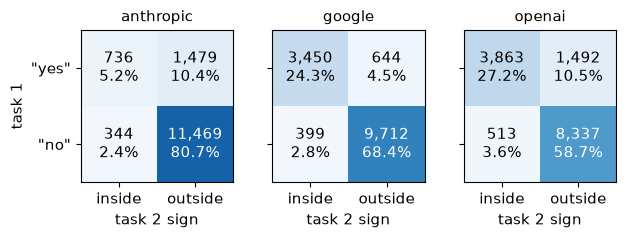

In [5]:
# task 1 answer vs sign of task 2 on the same analysed primary pins (unweighted counts; shares over all pins,
# so pins with an invalid answer are not shown but stay in the denominator, as in task_agreement_<model>)
import pandas as pd

from thesis.config import load_config

excluded = {entry["source_id"] for entry in load_config("scoring")["excluded_sources"]}
answers = pd.read_parquet(REPO_ROOT / "data" / "dataset_v2" / "main_run" / "answers.parquet")
answers = answers.loc[(answers["purpose"] == "primary") & ~answers["source_id"].isin(excluded)]
task1 = answers.loc[answers["task"] == "verification", ["model", "pin_id", "parsed_answer"]]
task2 = answers.loc[answers["task"] == "distance", ["model", "pin_id", "parsed_answer"]]
task2 = task2.assign(
    sign=np.select(
        [
            pd.to_numeric(task2["parsed_answer"], errors="coerce") <= 0,
            pd.to_numeric(task2["parsed_answer"], errors="coerce") > 0,
        ],
        ["inside", "outside"],
        "invalid",
    )
)
pairs = task1.merge(task2[["model", "pin_id", "sign"]], on=["model", "pin_id"])
n_pins = pairs.groupby("model").size()
pairs = pairs.loc[pairs["parsed_answer"].isin(["yes", "no"]) & (pairs["sign"] != "invalid")]

fig, axes = plt.subplots(1, len(MODELS), figsize=(width, 0.36 * width), sharey=True)
for ax, (m, group) in zip(axes, pairs.groupby("model")):
    table = pd.crosstab(group["parsed_answer"], group["sign"]).reindex(
        index=["yes", "no"], columns=["inside", "outside"]
    )
    ax.imshow(table, cmap="Blues", vmin=0, vmax=n_pins[m])
    for (i, j), n in np.ndenumerate(table.to_numpy()):
        ax.text(
            j,
            i,
            f"{n:,}\n{n / n_pins[m]:.1%}",
            ha="center",
            va="center",
            color="white" if n > n_pins[m] / 2 else "black",
        )
    ax.set_xticks([0, 1], table.columns)
    ax.set_yticks([0, 1], [f'"{a}"' for a in table.index])
    ax.set_title(m)
    ax.set_xlabel("task 2 sign")
axes[0].set_ylabel("task 1")
fig.savefig(image_dir / "task_cross_table.pdf")

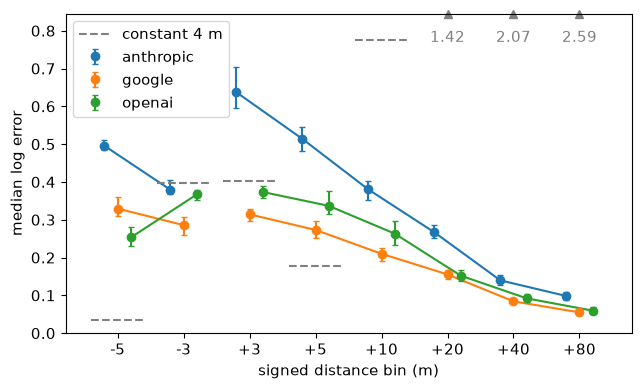

In [6]:
# median log error per bin with 95% CI error bars, joined within each side, best-constant baseline
fig, ax = plt.subplots()
inside = np.array(BINS) < 0
for i, m in enumerate(MODELS):
    keys = [f"distance_log_error_{m}_{bin_key(b)}" for b in BINS]
    err = np.array([results[k] for k in keys])
    low = np.array([results[f"{k}_ci_low"] for k in keys])
    high = np.array([results[f"{k}_ci_high"] for k in keys])
    x = np.arange(len(BINS)) + (i - 1) * 0.2
    color = ax.errorbar(x, err, yerr=[err - low, high - err], fmt="o", capsize=2, label=m)[0].get_color()
    for side in (inside, ~inside):  # gap at the edge
        ax.plot(x[side], err[side], color=color)
baseline = np.array([results[f"baseline_log_error_{bin_key(b)}"] for b in BINS])
# one flat segment per bin, not connected: the baseline is a per-bin value, nothing is interpolated between bins
ax.hlines(
    baseline,
    np.arange(len(BINS)) - 0.4,
    np.arange(len(BINS)) + 0.4,
    color="grey",
    linestyle="--",
    label=f"constant {results['baseline_constant_m']} m",
)
# y-axis scaled to the models; baseline points above it are clipped and labelled with their value
top = 1.2 * max(results[f"distance_log_error_{m}_{bin_key(b)}_ci_high"] for m in MODELS for b in BINS)
ax.set_ylim(0, top)
for x, value in enumerate(baseline):
    if value > top:
        ax.plot(x, top, marker="^", color="grey", clip_on=False)
        ax.annotate(
            f"{value:.2f}", (x, top), xytext=(0, -12), textcoords="offset points", ha="center", va="top", color="grey"
        )
ax.set_xticks(range(len(BINS)), [f"{b:+d}" for b in BINS])
ax.set_xlabel("signed distance bin (m)")
ax.set_ylabel("median log error")
ax.legend(loc="upper left")
fig.savefig(image_dir / "log_error_by_bin.pdf")

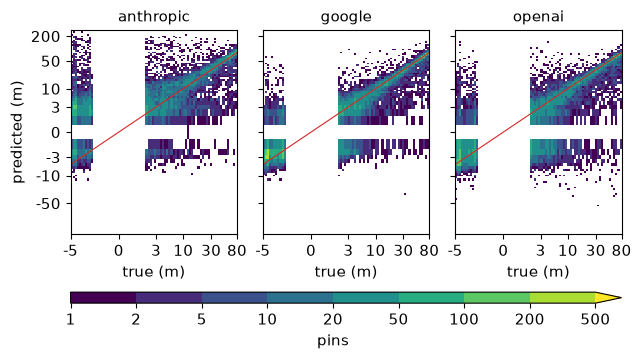

In [7]:
# predicted vs true signed distance, signed log axes, 2D histogram per model (analysed primary pins, unweighted)
# x: 80 columns; y: same log step, but never finer than the 1 m answer resolution (no empty integer rows)
import pandas as pd
from matplotlib.colors import BoundaryNorm

from thesis.config import load_config

data_dir = REPO_ROOT / "data" / "dataset_v2"
excluded = {entry["source_id"] for entry in load_config("scoring")["excluded_sources"]}
answers = pd.read_parquet(data_dir / "main_run" / "answers.parquet")
distance = answers.loc[
    (answers["task"] == "distance") & (answers["purpose"] == "primary") & ~answers["source_id"].isin(excluded)
]
distance = distance.assign(predicted=pd.to_numeric(distance["parsed_answer"], errors="coerce")).dropna(
    subset="predicted"
)


def signed_log(x):
    return np.sign(x) * np.log10(1 + np.abs(x))


x_edges = np.linspace(signed_log(-5), signed_log(80), 81)
step = x_edges[1] - x_edges[0]
half = [0.5]  # half-integer edges, one integer per row at least
while half[-1] < distance["predicted"].abs().max():
    half.append(max(half[-1] + 1, np.ceil((1 + half[-1]) * 10**step - 1.5) + 0.5))
y_edges = signed_log(np.array([-h for h in half[::-1]] + half))

levels = [1, 2, 5, 10, 20, 50, 100, 200, 500]
norm = BoundaryNorm(levels, plt.get_cmap("viridis").N, extend="max")
fig, axes = plt.subplots(1, len(MODELS), figsize=(width, 0.55 * width), sharex=True, sharey=True)
for ax, (m, group) in zip(axes, distance.groupby("model")):
    *_, image = ax.hist2d(
        signed_log(group["exact_signed_distance_m"]),
        signed_log(group["predicted"]),
        bins=[x_edges, y_edges],
        cmin=1,
        norm=norm,
        cmap="viridis",
        rasterized=True,
    )
    ax.plot(x_edges[[0, -1]], x_edges[[0, -1]], color="tab:red", linewidth=0.8)
    ax.set_title(m)
    ax.set_xlabel("true (m)")
x_ticks, y_ticks = np.array([-5, 0, 3, 10, 30, 80]), np.array([-50, -10, -3, 0, 3, 10, 50, 200])
ax.set_xticks(signed_log(x_ticks), x_ticks)
ax.set_yticks(signed_log(y_ticks), y_ticks)
axes[0].set_ylabel("predicted (m)")
fig.colorbar(image, ax=axes, orientation="horizontal", location="bottom", label="pins", aspect=50)
fig.savefig(image_dir / "predicted_vs_true.pdf")

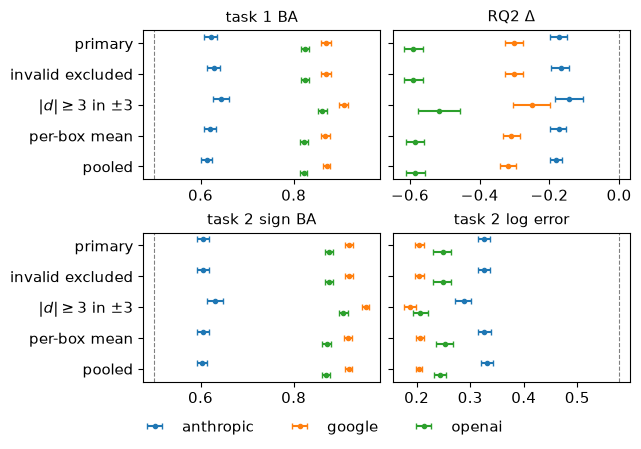

In [8]:
# sensitivity forest plot: one panel per metric, one row per variant, 95% CI; grey line = null / pass threshold
METRICS = {
    "verification_ba": ("task 1 BA", 0.5),
    "rq2_delta": (r"RQ2 $\Delta$", 0),
    "distance_sign_ba": ("task 2 sign BA", 0.5),
    "distance_log_error": ("task 2 log error", 0.578),  # best-constant baseline
}
VARIANTS = {
    "": "primary",
    "_invalid_excluded": "invalid excluded",
    "_d_ge3": r"$|d| \geq 3$ in $\pm3$",
    "_per_box_mean": "per-box mean",
    "_pooled": "pooled",
}

fig, axes = plt.subplots(2, 2, figsize=(width, 0.7 * width), sharey=True)
axes[1, 0].sharex(axes[0, 0])  # both BA panels on one scale
for ax, (metric, (title, reference)) in zip(axes.flat, METRICS.items()):
    for i, m in enumerate(MODELS):
        keys = [f"{metric}_{m}{suffix}" for suffix in VARIANTS]
        value = np.array([results[k] for k in keys])
        low = np.array([results[f"{k}_ci_low"] for k in keys])
        high = np.array([results[f"{k}_ci_high"] for k in keys])
        y = np.arange(len(VARIANTS)) + (i - 1) * 0.2
        ax.errorbar(value, y, xerr=[value - low, high - value], fmt="o", markersize=3, capsize=2, label=m)
    ax.axvline(reference, color="grey", linestyle="--", linewidth=0.8)
    ax.set_title(title)
axes[0, 0].set_yticks(range(len(VARIANTS)), VARIANTS.values())
axes[0, 0].invert_yaxis()
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=len(MODELS), frameon=False)
fig.savefig(image_dir / "sensitivity.pdf")

'00b7eb9e-1ce9-4265-a41e-7de125612cd7'

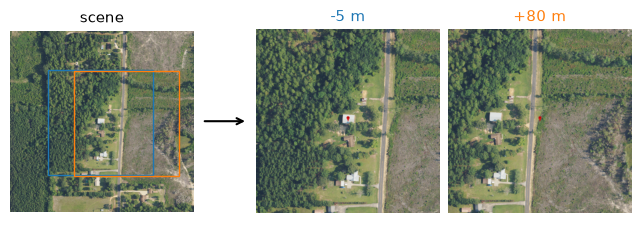

In [9]:
# example: full scene -> crops of one building at -5 m and +80 m; rerun for the next building
import hashlib

import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image
from rasterio.windows import Window

from thesis.config import load_config
from thesis.data import naip

if "example_sources" not in globals():
    data_dir = REPO_ROOT / "data" / "dataset_v2"
    sources = pd.read_parquet(data_dir / "selection" / "sources.parquet").set_index("source_id")
    pins = pd.read_parquet(data_dir / "audit" / "selected_pins.parquet").query("bin_id in [-5, 80]")
    pins = pins[pins["source_id"].map(sources["assignment"]) == "main"]
    pins["render"] = [
        data_dir / "renders" / f"{hashlib.sha256(f'{p}:google_pin_red:unchanged'.encode()).hexdigest()}.png"
        for p in pins["pin_id"]
    ]
    pins = pins[pins["render"].map(lambda p: p.exists())]
    example_sources = iter(pins.groupby("source_id").filter(lambda g: len(g) == 2).groupby("source_id"))

source_id, example = next(example_sources)
source = sources.loc[source_id]
cache_key = naip.window_cache_key(source["naip_item_id"], Window(*map(int, source["scene_window"])))
scene = naip.load_cached(REPO_ROOT / load_config("imagery")["scene_cache_dir"], cache_key).array

fig, axes = plt.subplots(1, 4, figsize=(width, 0.36 * width), width_ratios=[1, 0.25, 1, 1])
axes[0].imshow(scene.transpose(1, 2, 0))
axes[0].set_title("scene")
axes[1].annotate("", xy=(1, 0.5), xytext=(0, 0.5), arrowprops=dict(arrowstyle="->", lw=1.5))
for ax, (_, pin), color in zip(axes[2:], example.sort_values("bin_id").iterrows(), ["tab:blue", "tab:orange"]):
    ax.imshow(Image.open(pin["render"]))
    ax.set_title(f"{pin['bin_id']:+d} m", color=color)
    col, row, w, h = pin["crop_window"]
    axes[0].add_patch(Rectangle((col, row), w, h, fill=False, edgecolor=color))
for ax in axes:
    ax.set_axis_off()
fig.savefig(image_dir / "example_crops.pdf")
source_id

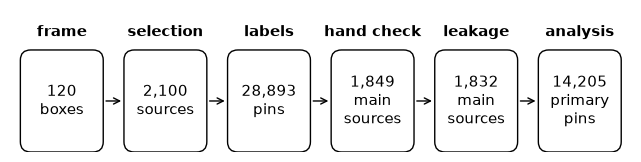

In [10]:
from matplotlib.patches import FancyBboxPatch

# pipeline: stage headline above, count in box
stages = [
    ("frame", "120\nboxes"),
    ("selection", "2,100\nsources"),
    ("labels", "28,893\npins"),
    ("hand check", "1,849\nmain\nsources"),
    ("leakage", "1,832\nmain\nsources"),
    ("analysis", f"{results['n_primary_pins']:,}\nprimary\npins"),
]
fig, ax = plt.subplots(figsize=(width, 0.24 * width))
for i, (stage, count) in enumerate(stages):
    ax.add_patch(FancyBboxPatch((i - 0.4, 0), 0.8, 1, boxstyle="round,pad=0,rounding_size=0.1", fill=False))
    ax.text(i, 0.5, count, ha="center", va="center")
    ax.text(i, 1.1, stage, ha="center", va="bottom", weight="bold")
    if i:
        ax.annotate("", xy=(i - 0.4, 0.5), xytext=(i - 0.6, 0.5), arrowprops=dict(arrowstyle="->"))
ax.set(xlim=(-0.5, len(stages) - 0.5), ylim=(0, 1.4))
ax.set_axis_off()
fig.savefig(image_dir / "pipeline.pdf")

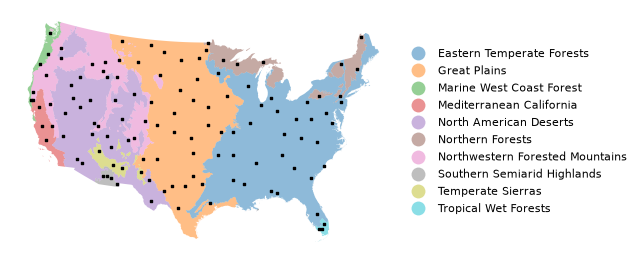

In [11]:
# sampling frame: CEC Level-I ecoregions with the 120 selected boxes
import geopandas as gpd

from thesis.config import load_config

sampling_config = load_config("sampling")
crs = sampling_config["sampling_frame"]["bbox_grid"]["crs"]
states = gpd.read_file(REPO_ROOT / sampling_config["conus"]["path"])
states = states[states["REGION"].astype(str).isin(["1", "2", "3", "4"]) & ~states["STUSPS"].isin(["AK", "HI"])].to_crs(
    crs
)
ecoregions = gpd.read_file(REPO_ROOT / sampling_config["ecoregions"]["path"])
ecoregions = (
    ecoregions[ecoregions["NA_L1CODE"] != "0"].to_crs(crs).dissolve(by=["NA_L1CODE", "NA_L1NAME"], as_index=False)
)
ecoregions = gpd.clip(ecoregions, states.union_all())
ecoregions["label"] = ecoregions["NA_L1NAME"].str.title()
boxes = gpd.read_parquet(REPO_ROOT / "data" / "dataset_v2" / "inventory" / "boxes.parquet").to_crs(crs)

fig, ax = plt.subplots(figsize=(width, 0.7 * width))
ecoregions.plot(
    column="label",
    ax=ax,
    categorical=True,
    cmap="tab10",
    alpha=0.5,
    legend=True,
    legend_kwds={"loc": "center left", "bbox_to_anchor": (1, 0.5), "frameon": False, "fontsize": 8},
)
boxes.centroid.plot(ax=ax, marker="s", markersize=3, color="black")
boxes.plot(ax=ax, color="black")
ax.set_axis_off()
fig.savefig(image_dir / "sampling_frame.pdf")

(196, np.float64(-0.45979477763455856), np.float64(2.8274892592819483))

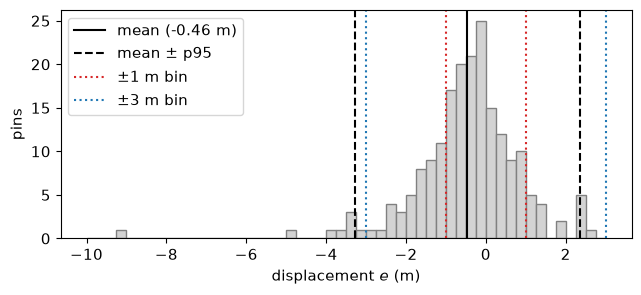

In [12]:
# edge displacement e (+ = visible roof edge outside the footprint edge), from the clicked ±1 m pins
import geopandas as gpd
import pandas as pd
from shapely import from_wkb
from shapely.geometry import Point
from shapely.ops import nearest_points

from thesis.config import load_config
from thesis.data.eligibility import context_for_scene
from thesis.run import _geometry_to_crs, _valid_context_footprints

data_dir = REPO_ROOT / "data" / "dataset_v2"
marks = pd.read_json(data_dir / "gold" / "edge_marks_phillip.jsonl", lines=True).query("~skipped")
clicked = (
    marks[["pin_id", "click_x", "click_y"]]
    .merge(pd.read_parquet(data_dir / "audit" / "selected_pins.parquet"), on="pin_id")
    .merge(
        pd.read_parquet(data_dir / "selection" / "sources.parquet")[
            ["source_id", "naip_source_crs", "scene_geometry_wkb"]
        ],
        on="source_id",
    )
)
footprints = _valid_context_footprints(gpd.read_parquet(REPO_ROOT / load_config("overture")["out"]))


def displacement(row):
    scene = _geometry_to_crs(from_wkb(row["scene_geometry_wkb"]), "EPSG:5070", "EPSG:4326")
    edge = context_for_scene(footprints, scene).to_crs(row["naip_source_crs"]).union_all().boundary
    pin = np.array([row["tip_x"], row["tip_y"]])
    r = np.array(nearest_points(edge, Point(pin))[0].coords[0])
    e = (np.array([row["click_x"], row["click_y"]]) - r) @ ((r - pin) / np.linalg.norm(r - pin))
    return -e if row["exact_signed_distance_m"] > 0 else e


e = clicked.apply(displacement, axis=1)
mean = e.mean()
p95 = (e - mean).abs().quantile(0.95)

fig, ax = plt.subplots(figsize=(width, 0.45 * width))
ax.hist(e, bins=np.arange(np.floor(e.min()), np.ceil(e.max()) + 0.25, 0.25), color="lightgrey", edgecolor="grey")
ax.axvline(mean, color="black", label=f"mean ({mean:.2f} m)")
for x in (mean - p95, mean + p95):
    ax.axvline(x, color="black", linestyle="--", label=r"mean $\pm$ p95" if x < mean else None)
for b, color in ((1, "tab:red"), (3, "tab:blue")):
    for x in (-b, b):
        ax.axvline(x, color=color, linestyle=":", label=rf"$\pm{b}$ m bin" if x < 0 else None)
ax.set_xlabel("displacement $e$ (m)")
ax.set_ylabel("pins")
ax.legend()
fig.savefig(image_dir / "edge_displacement.pdf")
len(e), mean, p95

env: DYLD_FALLBACK_LIBRARY_PATH=/opt/homebrew/lib


({'google_pin_red': 0.709,
  'google_pin_neon_blue': 0.6828,
  'google_pin_neon_green': 0.6935,
  'dot_red': 0.6829,
  'dot_neon_blue': 0.6801,
  'dot_neon_green': 0.6784,
  'crosshair_red': 0.702,
  'crosshair_neon_blue': 0.6937,
  'crosshair_neon_green': 0.7032},
 {'details': 0.6933,
  'minimal': 0.6566,
  'roleplaying': 0.702,
  'some_details': 0.6667,
  'super_detailed_and_role': 0.6885})

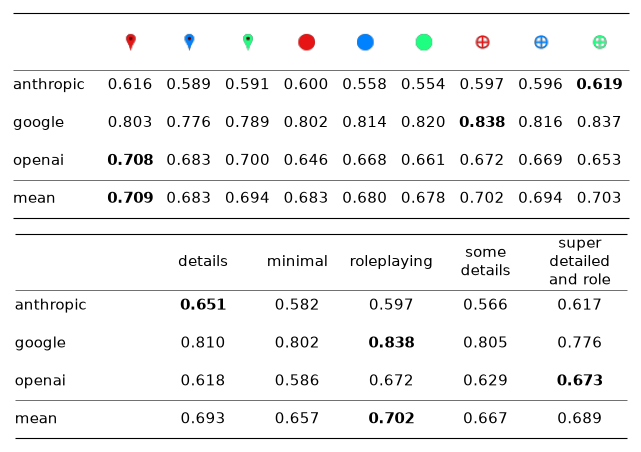

In [13]:
%env DYLD_FALLBACK_LIBRARY_PATH=/opt/homebrew/lib
# v1 selection: macro F1 per provider for the 9 markers (roleplaying prompt) and the 5 prompts (crosshair red)
# invalid answers dropped, as in notebooks/ablations/phi44_select_*.ipynb
import hashlib
import textwrap

import duckdb
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from sklearn.metrics import f1_score

from thesis.config import load_config
from thesis.render.marker import draw_marker, marker_hotspot
from thesis.render.presets import load_presets
from thesis.vlm.vlm_adapter import VLMResponse

ablation_dir = REPO_ROOT / "data" / "ablation"
prompt_ids = {hashlib.sha256(p["text"].encode()).hexdigest(): p["id"] for p in load_config("prompts")["prompts"]}
responses = (
    pd.DataFrame(
        [
            (r.provider, r.image_sha256, prompt_ids.get(r.prompt_sha256), r.parsed_answer, r.timestamp)
            for r in (
                VLMResponse.model_validate_json(f.read_text())
                for f in (REPO_ROOT / "data" / "vlm_cache").glob("*/*.json")
            )
        ],
        columns=["provider", "image_sha256", "prompt_id", "parsed_answer", "timestamp"],
    )
    .sort_values("timestamp")
    .drop_duplicates(["provider", "image_sha256", "prompt_id"])
)  # drop the later 16k-cap retest
with duckdb.connect(str(ablation_dir / "manifest.duckdb"), read_only=True) as connection:
    samples = connection.sql("SELECT * FROM samples").df()
samples["image_sha256"] = [hashlib.sha256((ablation_dir / p).read_bytes()).hexdigest() for p in samples["image_path"]]
samples = samples.sort_values("include_in_distance_curve", ascending=False).drop_duplicates("image_sha256")
v1 = responses.merge(samples, on="image_sha256").query("parsed_answer in ['yes', 'no']")


def macro_f1(group):
    return f1_score(group["ground_truth_inside"], group["parsed_answer"] == "yes", average="macro")


presets = load_presets(load_config("render"))
v1["marker"] = (
    v1["marker_shape"] + "_" + v1["marker_color"].map({str(p["color"]): p["color_name"] for p in presets.values()})
)
markers = (
    v1.query("prompt_id == 'roleplaying'").groupby(["provider", "marker"]).apply(macro_f1).unstack()[list(presets)]
)
prompts = v1.query("marker == 'crosshair_red'").groupby(["provider", "prompt_id"]).apply(macro_f1).unstack()


def icon(preset, px=24):
    hotspot_y = marker_hotspot(preset["shape"], preset["size_px"])[1]
    canvas = np.full((3, px, px), 255, dtype=np.uint8)
    return draw_marker(
        canvas,
        px // 2,
        px // 2 + hotspot_y - preset["size_px"] // 2,
        preset["shape"],
        preset["color"],
        preset["size_px"],
        preset["opacity"],
    ).transpose(1, 2, 0)


def table(ax, values, headers):
    # booktabs look: top/bottom rule, midrule under the header, light rule above the selection criterion
    values = pd.concat([values, values.mean().to_frame("mean").T])
    x0, x1 = -1, len(headers) + 0.5
    for j, header in enumerate(headers, start=1):
        if isinstance(header, str):
            ax.text(j, -0.15, header, ha="center", va="center")
        else:
            ax.add_artist(AnnotationBbox(OffsetImage(header, zoom=0.8), (j, -0.15), frameon=False))
    for i, (label, row) in enumerate(values.iterrows(), start=1):
        ax.text(x0, i, label, ha="left", va="center")
        for j, value in enumerate(row, start=1):
            ax.text(j, i, f"{value:.3f}", ha="center", va="center", weight="bold" if value == row.max() else "normal")
    ax.hlines([-0.9, len(values) + 0.5], x0, x1, color="black", linewidth=0.8)
    ax.hlines([0.6, len(values) - 0.5], x0, x1, color="black", linewidth=0.4)
    ax.set(xlim=(x0 - 0.05, x1 + 0.05), ylim=(len(values) + 0.6, -1.0))
    ax.set_axis_off()


fig, axes = plt.subplots(2, 1, figsize=(width, 0.7 * width))
table(axes[0], markers, [icon(presets[m]) for m in markers.columns])
table(axes[1], prompts, [textwrap.fill(p.replace("_", " "), 9, break_long_words=False) for p in prompts.columns])
fig.savefig(image_dir / "ablation_f1.pdf")
markers.mean().round(4).to_dict(), prompts.mean().round(4).to_dict()

In [14]:
# numbers.tex: definitions only; \result is in the preamble
def fmt(key, value):
    if isinstance(value, bool):
        return "yes" if value else "no"
    if isinstance(value, int):
        return f"{value:,}"
    if isinstance(value, float):
        # p-values floor at 1/10,001
        return f"{value:.4f}" if key.startswith("p_") else f"{value:.3f}"
    return str(value)


lines = [
    rf"\expandafter\def\csname result@{k}\endcsname{{{fmt(k, v)}}}"
    for k, v in (results | json.loads((REPO_ROOT / "results" / "analysis.json").read_text())).items()
]
(export_dir / "numbers.tex").write_text("\n".join(lines) + "\n")
len(results)

1082